# 04 · Expression — EMT-transcription-factor axis (Nam et al. 2019)

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly.)*

Per the **derive-don't-inherit** mandate we do not copy Puram's SNAI1/ZEB1 pair. A candidate
EMT-TF panel — canonical Snail/Zeb/Twist **plus the mesenchymal FOXC and PRRX families** — is
scored along *this* trajectory, gated on detectable expression (≥3% of cells; sparser factors
honestly excluded), and the data pick the most end-specific expressed factor at each end. VIM is
a mesenchymal marker, not a TF, and is excluded. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.stats import spearmanr

In [1]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted, signature-scored manifold (house linear layout)

In [1]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 22605 | pseudotime range 0.0 -> 13.77


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction expressing, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative
correlation (sufficiently expressed) marks the root end; most positive marks the terminus.
Factors below a 3% expression floor are too sparse to overlay.

In [1]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('candidate TFs present in data:', present)
print('candidate TFs absent:', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nexpressed TFs (>3%): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

candidate TFs present in data: ['SNAI1', 'ZEB1', 'ZEB2', 'TWIST1', 'FOXC1', 'FOXC2', 'PRRX2']
candidate TFs absent: ['SNAI2', 'TWIST2', 'PRRX1']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI1      0.005       0.004      0.001    -0.008    EARLY(root)
 FOXC1      0.000       0.000      0.000    -0.003 LATE(terminus)
 FOXC2      0.000       0.000      0.000     0.000 LATE(terminus)
 PRRX2      0.000       0.000      0.000    -0.000 LATE(terminus)
  ZEB1      0.103       0.091      0.063     0.005    EARLY(root)
TWIST1      0.051       0.039      0.032     0.021    EARLY(root)
  ZEB2      0.662       0.570      0.648     0.081 LATE(terminus)

expressed TFs (>3%): ['ZEB1', 'TWIST1', 'ZEB2']
derived pair: ZEB1 (early/root) <-> ZEB2 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style `(3.5,1.5)`, pseudotime left→right, `size=30`, **categorical overlay** of thresholded
expressers on a grey manifold (not a continuous single-gene colormap). The abundant marker is
drawn first so the sparser marker reads on top; each factor is thresholded at the upper quartile
among its expressing cells so the display is not outlier-washed.

overlay thresholds (upper quartile among expressers): {'ZEB1': 0.811, 'ZEB2': 1.255} | cells shown: {'ZEB1': 580, 'ZEB2': 3742}
ZEB1: 10.3% expressing; 580 shown (upper quartile), mean pseudotime of shown cells = 0.23 (all cells = 0.51)
ZEB2: 66.2% expressing; 3742 shown (upper quartile), mean pseudotime of shown cells = 0.47 (all cells = 0.51)
shown-cell pseudotime separation (ZEB1 vs ZEB2) = 0.24
saved expression.pdf


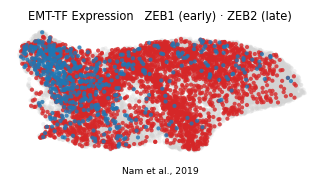

In [1]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) \u00b7 {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Nam et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')